In [69]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import root_mean_squared_error

In [70]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [71]:
device

device(type='cpu')

In [72]:
ticker = 'AAPL'
df = yf.download(ticker, '2020-01-01')

[*********************100%***********************]  1 of 1 completed


In [73]:
df

Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2020-01-02,72.216682,72.276793,70.976002,71.228463,135480400
2020-01-03,71.514572,72.271962,71.290963,71.447249,146322800
2020-01-06,72.084419,72.122891,70.389308,70.639370,118387200
2020-01-07,71.745407,72.348911,71.526604,72.094043,108872000
2020-01-08,72.899536,73.200088,71.449673,71.449673,132079200
...,...,...,...,...,...
2026-11-10,348.245392,353.601307,346.196930,351.083232,29756100
2026-11-11,355.359985,355.639772,349.064750,349.284585,34453500


<Axes: xlabel='Date'>

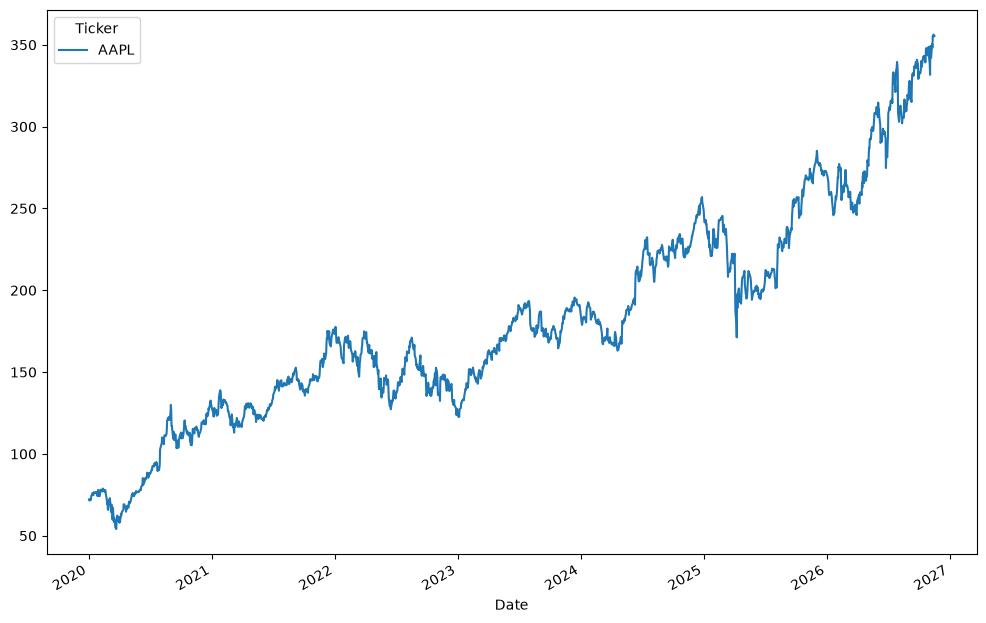

In [74]:
df.Close.plot(figsize=(12,8))

In [75]:
scaler = StandardScaler()
df['Close'] = scaler.fit_transform(df['Close'])

In [76]:
df.Close

Ticker,AAPL
Date,
2020-01-02,-1.675372
2020-01-03,-1.686158
2020-01-06,-1.677404
2020-01-07,-1.682612
2020-01-08,-1.664883
...,...
2026-11-10,2.564755
2026-11-11,2.674044
2026-11-12,2.666671


In [77]:
seq_length = 30
data = []

for i in range(len(df) - seq_length):
    data.append(df.Close[i:i+seq_length])

data = np.array(data)

In [78]:
data

array([[[-1.67537246],
        [-1.6861577 ],
        [-1.67740418],
        ...,
        [-1.60143457],
        [-1.57333459],
        [-1.58196119]],

       [[-1.6861577 ],
        [-1.67740418],
        [-1.6826118 ],
        ...,
        [-1.57333459],
        [-1.58196119],
        [-1.58166504]],

       [[-1.67740418],
        [-1.6826118 ],
        [-1.66488302],
        ...,
        [-1.58196119],
        [-1.58166504],
        [-1.60369295]],

       ...,

       [[ 2.28554783],
        [ 2.33727556],
        [ 2.32499618],
        ...,
        [ 2.5982174 ],
        [ 2.56475545],
        [ 2.67404403]],

       [[ 2.33727556],
        [ 2.32499618],
        [ 2.33635487],
        ...,
        [ 2.56475545],
        [ 2.67404403],
        [ 2.66667096]],

       [[ 2.32499618],
        [ 2.33635487],
        [ 2.38301737],
        ...,
        [ 2.67404403],
        [ 2.66667096],
        [ 2.68802276]]], shape=(1698, 30, 1))

In [79]:
train_size = int(0.8 * len(data))

x_train = torch.from_numpy(data[:train_size, :-1, :]).type(torch.Tensor).to(device)
y_train = torch.from_numpy(data[:train_size, -1, :]).type(torch.Tensor).to(device)
x_test = torch.from_numpy(data[train_size:, :-1, :]).type(torch.Tensor).to(device)
y_test = torch.from_numpy(data[train_size:, -1, :]).type(torch.Tensor).to(device)

In [80]:
y_train

tensor([[-1.5820],
        [-1.5817],
        [-1.6037],
        ...,
        [ 0.4233],
        [ 0.4406],
        [ 0.4600]])

In [81]:
class PredictionModel(nn.Module):
    
    def __init__(self, input_dim, hidden_dim, num_layers, output_dim):
        super(PredictionModel, self).__init__()

        self.num_layers = num_layers
        self.hidden_dim = hidden_dim

        self.lstm = nn.LSTM(input_dim, hidden_dim, num_layers, batch_first = True)
        self.fc = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        h0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)
        c0 = torch.zeros(self.num_layers, x.size(0), self.hidden_dim, device=device)

        out, (hn, cn) = self.lstm(x, (h0.detach(), c0.detach()))
        out = self.fc(out[:, -1, :])

        return out

In [82]:
model = PredictionModel(input_dim=1, hidden_dim=32, num_layers=2, output_dim=1).to(device)

In [83]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

In [84]:
num_epochs = 200

for i in range(num_epochs):
    y_train_pred = model(x_train)

    loss = criterion(y_train_pred, y_train)

    if i % 25 == 0:
        print(i, loss)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

0 tensor(0.6883, grad_fn=<MseLossBackward0>)
25 tensor(0.0184, grad_fn=<MseLossBackward0>)
50 tensor(0.0050, grad_fn=<MseLossBackward0>)
75 tensor(0.0041, grad_fn=<MseLossBackward0>)
100 tensor(0.0038, grad_fn=<MseLossBackward0>)
125 tensor(0.0036, grad_fn=<MseLossBackward0>)
150 tensor(0.0033, grad_fn=<MseLossBackward0>)
175 tensor(0.0031, grad_fn=<MseLossBackward0>)


In [85]:
model.eval()

y_test_pred = model(x_test)

y_train_pred = scaler.inverse_transform(y_train_pred.detach().cpu().numpy())
y_train = scaler.inverse_transform(y_train.detach().cpu().numpy())
y_test_pred = scaler.inverse_transform(y_test_pred.detach().cpu().numpy())
y_test = scaler.inverse_transform(y_test.detach().cpu().numpy())

In [86]:
train_rmse = root_mean_squared_error(y_train[:, 0], y_train_pred[:, 0])
test_rmse = root_mean_squared_error(y_test[:, 0], y_test_pred[:, 0])

In [87]:
train_rmse

3.557304859161377

In [88]:
test_rmse

13.611328125

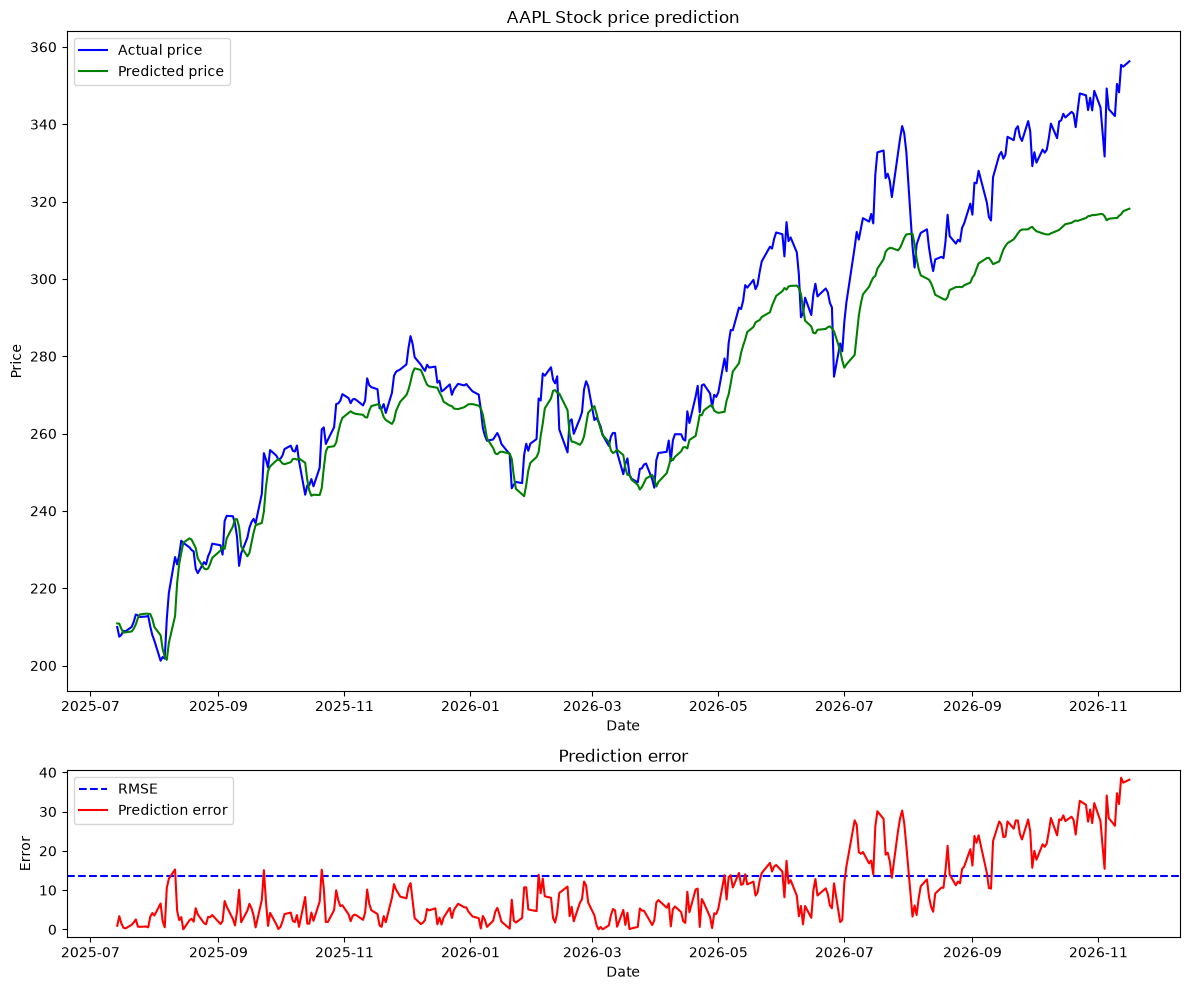

In [89]:
fig = plt.figure(figsize=(12, 10))

gs = fig.add_gridspec(4, 1)

ax1 = fig.add_subplot(gs[:3, 0])
ax1.plot(df.iloc[-len(y_test):].index, y_test, color = 'blue', label = 'Actual price')
ax1.plot(df.iloc[-len(y_test):].index, y_test_pred, color = 'green', label = 'Predicted price')
ax1.legend()
plt.title(f"{ticker} Stock price prediction")
plt.xlabel('Date')
plt.ylabel('Price')

ax2 = fig.add_subplot(gs[3, 0])
ax2.axhline(test_rmse, color = 'blue', linestyle = '--', label='RMSE')
ax2.plot(df[-len(y_test):].index, abs(y_test-y_test_pred), 'r', label = 'Prediction error')
ax2.legend()
plt.title('Prediction error')
plt.xlabel('Date')
plt.ylabel('Error')

plt.tight_layout()
plt.show()